In [1]:
# import necessary library
import numpy as np  #numpy: https://numpy.org/doc/stable/index.html
import importlib.util  #importlib: https://docs.python.org/3/library/importlib.html
import pylab as pl #plotting library

import matplotlib
import matplotlib.pyplot as plt
# matplotlib.rcParams.update({'font.size': 18, 'font.family': 'Times'})

import decorate as decorate
import fitsio as F # fitsio to read and write fits files

import time

def ltime(date=False):
    tm=time.localtime()
    datestr=str(tm.tm_mday)+'/'+str(tm.tm_mon)+'/'+str(tm.tm_year)
    tmstr=str(tm.tm_hour)+':'+str(tm.tm_min)+':'+str(tm.tm_sec)

    if(date):
        tmstr=datestr+' '+tmstr

    return tmstr

import sys
sys.path.append("/mnt/home/project/csatsangi.chetan/projects/modified_poisson")
sys.path.append("spectrophotogroup/Simulator")
sys.path.append("sahyadri-sandbox/scripts/post-process")
import simulator
np.int=int
from readers import HaloReader
from readers import SnapshotReader

In [19]:
# HOD Parameters given by shadab:
# HOD parameter chosen from Table 2 , first column of https://arxiv.org/pdf/2305.01266.pdf
#This is to fix the random number while generating galaxies
random_seed=10

halo_ftype='fits_Bolshoi'
central_model='erf'
satellite_model='power_law'
angular_distribution='spherical'
radial_profile='NFW'
los='z'
geometry='cubic'
z_cos = 0.1
Mcut=np.power(10,11.71)
M1=np.power(10,12.08)
sigma=0.81
pmax =1.0
alpha=0.49
kappa=2.47
verbose=True
return_full_obj=True
#parameter defined but not used with this setting
Ap = 1.0
fradsat=1.0
fconc=1.0
gNFW=1.0
Q=None
gamma=4.12 
alpha_einasto=0.16
constant_nsat=2        

In [3]:
import scipy as sp
def fcen_erf(M, Mcut, sigma):
    mean_ncen = 0.5*(sp.special.erfc(np.log10(Mcut/M)/(math.sqrt(2)*np.log10(math.e)*sigma)))
    return mean_ncen

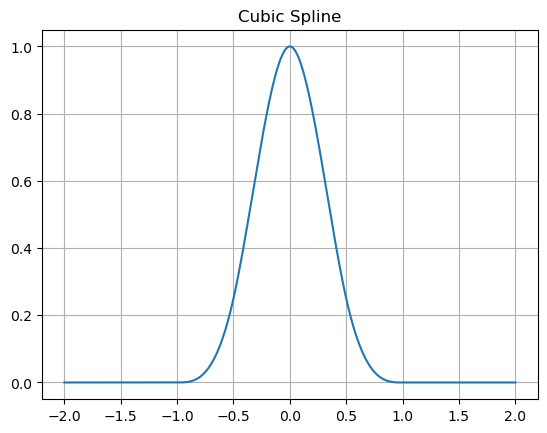

In [4]:
def spline(x):
    abs_x = np.abs(x)
    
    conditions = [
        abs_x <= 0.5,
        (abs_x > 0.5) & (abs_x <= 1.0)
    ]
    
    functions = [
        1 - 6 * abs_x**2 + 6 * abs_x**3,
        2 * (1 - abs_x)**3
    ]
    
    # Defaults to 0.0 for |x| > 1.0
    return np.select(conditions, functions, default=0.0)

# Plotting over (-2, 2)
x = np.linspace(-2, 2, 500)
y = spline(x)

plt.plot(x, y)
plt.title("Cubic Spline")
plt.grid(True)
plt.show()

In [5]:
def S(x):
    arg =  x/(np.sqrt(6.0))
    S = ((4.0/3.0)/(np.sqrt(6.0))) * spline(arg)
    return S

def F(x):
    t = x / np.sqrt(6)
    at = np.abs(t)
    sign = np.sign(x)

    piece1 = (8/3)*t - (16/3)*t**3 + 4*t**4
    piece2 = np.sign(t) * (1 - (4/3)*(1 - at)**4)
    piece3 = np.sign(t) * 1.0

    result = np.where(
        at <= 0.5, piece1,
        np.where(at <= 1, piece2, piece3)
    )
    return result

In [6]:
# READ the halo_Cat
real = 1
snap = 82
sim_stem = "sahyadri/default2048"
redshift = 0
hr = HaloReader(sim_stem= sim_stem, real=real, snap=snap)
hpos, halos = hr.prep_halos(massdef='mvir', QE=0.5,Npmin=0, sorthalos=False, keep_subhalos=True)

Snapshot Reader:
... preparing to read file: /data/project/hpc2502016/data/sims/sahyadri/default2048/r1/snapdir_082/snapshot_082
... loaded header and parameters
... preparing halo data
... using file: sahyadri/default2048/r1/out_82.trees
... ... using mass definition mvir > 0.000e+00 Msun/h
... ... only relaxed objects retained with 0.50 < 2T/|U| < 1.50
... ... kept 9679164 of 10493239 objects in catalog


In [7]:
def mean_ncen(M, Mcut, sigma):
    F_arg = (np.log10(M) - np.log10(Mcut))/sigma
    ncen = 0.5*(1 + F(F_arg))
    return ncen

In [8]:
M = halos['m200b']

In [9]:
y = mean_ncen(M, Mcut, sigma)

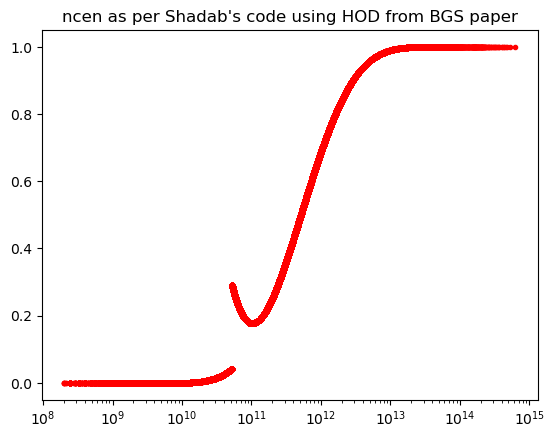

In [40]:
plt.plot(M, y, 'r.')
# plt.yscale('log')
plt.title("ncen as per Shadab's code using HOD from BGS paper")
plt.xscale('log')
plt.show()

In [19]:
y.shape[0]

9679164

In [10]:
# best-fit meta-parameters. Refer to arXiv:2312.08792v2 (DESI BGS)

_A_min, _B_min, _C_min, _D_min = -0.1163295942035853792, -0.5759066407274642252, 0.1437085418067726994, -0.01908335449679073731
_A_sig, _B_sig, _C_sig, _D_sig = 0.01832666435246161490, 0.7584865035087475782, 1.103103765754579246, 0.3277787214124110449
_A_0,   _B_0                    = -0.5468895455660652827, -1.673562380257160864
_A_1,   _B_1, _C_1, _D_1         = 1.121497360473139082, -0.4725625165007949491, 0.09200038944813740405, -0.01141762462160326314
_A_al,  _B_al, _C_al             = 1.111866664500087198, 4.473949866395862784, -4.353309870091147893


#Fitting functions for HOD Parameters:
def _M_function(Mr, A, B, C, D):
    x = Mr + 20
    return (A + 12) + B*x + C*x**2 + D*x**3          # returns log10(M)

def _M0_function(Mr, A, B):
    x = Mr + 20
    logM0 = (A + 11) + B*x
    return np.maximum(logM0, 1.0)                            # scalar-safe floor

def _sigma_function(Mr, A, B, C, D):
    x = Mr + 20
    return A + (B - A) / (1. + np.exp(C*(x + D)))

def _alpha_function(Mr, A, B, C):
    x = Mr + 20
    return A + B**(-x + C)

def hod_params_func(Mr):
    """Smith, Grove, Cole et al. (2024) nested BGS HOD, AbacusSummit c000/ph000 best fit.
    Returns Mcut, M1, sigma, alpha, kappa (kappa*Mcut == M0) for simulator.py's HOD_model.
    """
    logMmin = _M_function(Mr, _A_min, _B_min, _C_min, _D_min)
    logM1   = _M_function(Mr, _A_1,   _B_1,   _C_1,   _D_1)
    logM0   = _M0_function(Mr, _A_0, _B_0)
    sigma   = _sigma_function(Mr, _A_sig, _B_sig, _C_sig, _D_sig)
    alpha   = _alpha_function(Mr, _A_al, _B_al, _C_al)
    
    Mcut = 10**logMmin
    M1   = 10**logM1
    M0   = 10**logM0
    kappa = M0 / Mcut

    return dict(Mcut=Mcut, M1=M1, sigma=sigma, alpha=alpha, kappa=kappa)

In [13]:
hod_params = hod_params_func(-18.0) #since the BGS paper works with this number

random_seed=10

halo_ftype='fits_Bolshoi'
central_model='erf'
satellite_model='power_law'
angular_distribution='spherical'
radial_profile='NFW'
los='z'
geometry='cubic'
z_cos = 0.2
Mcut=hod_params['Mcut']
M1=hod_params['M1']
sigma=hod_params['sigma']
pmax =1.0
alpha=hod_params['alpha']
kappa=hod_params['kappa']
verbose=True
return_full_obj=True
#parameter defined but not used with this setting
Ap = 1.0
fradsat=1.0
fconc=1.0
gNFW=1.0
Q=None
gamma=4.12 
alpha_einasto=0.16
constant_nsat=2

In [14]:
y_bgs = mean_ncen(M, Mcut, sigma)

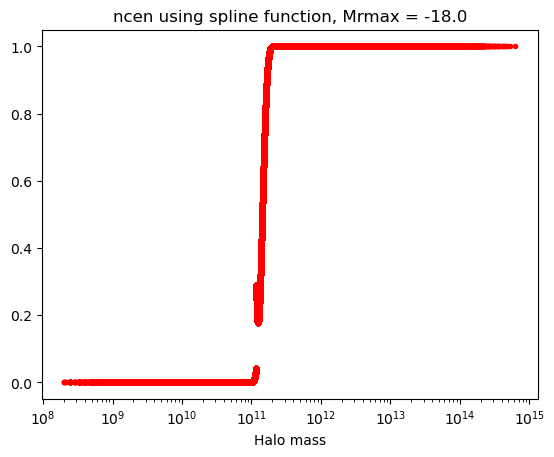

In [15]:
plt.plot(M, y_bgs, 'r.')
plt.xscale('log')
plt.xlabel('Halo mass')
# plt.yscale('log')
plt.title('ncen using spline function, Mrmax = -18.0')

plt.show()

In [16]:
import scipy as sp
import math
def erf_hod(M, Mcut, sigma):
    mean_ncen = 0.5*(sp.special.erfc(np.log10(Mcut/M)/(math.sqrt(2)*np.log10(math.e)*sigma)))
    return mean_ncen

In [20]:
ncen_shadab = erf_hod(M, Mcut, sigma)

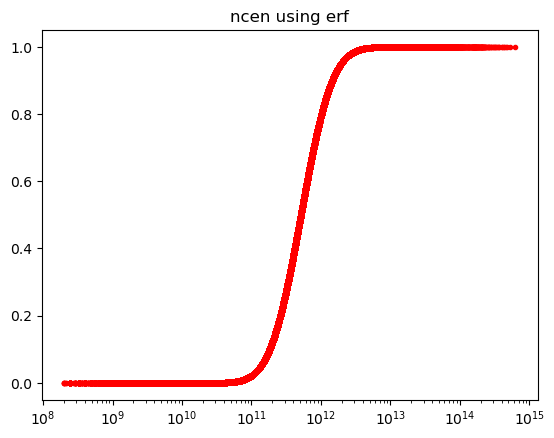

In [21]:
plt.plot(M, ncen_shadab, 'r.')
plt.xscale('log')
plt.title("ncen using erf")
plt.show()